# IRF systematics study: fixed counts, perturbed IRFs

The previous notebook on the joint crab shows that you can add nuissance parameters in the fit with custom models to take into account the systematic uncertainties.

This notebook shows that for modifications that are not trivial to include as models, we can create samples of datasets with modified IRFs and marginalise over realisation to get the systematic errors.


The idea is to keep the counts fixed and perturb the IRFs used in the fit:

- the counts are fixed
- draw random IRF variations (background norm, tilt, spatial gradient,
     and an energy-scale shift of exposure/edisp/psf).
- the same counts are re-fitted with the perturbed IRFs
- the spread of the fitted source parameters around the nominal fit is the systematic uncertainty.

In [20]:
import sys
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord, Angle
import astropy.units as u

from gammapy.datasets import Datasets
from gammapy.maps import Map, MapAxis, WcsGeom
from gammapy.modeling import Fit
from gammapy.modeling.models import FoVBackgroundModel, Models

import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

## Configuration

Here we setup the perturbation parameters for the IRFs. 

In [2]:
# Widths of the random IRF variations (Gaussian draws)
var_norm_bkg = 0.01         # relative background normalisation
var_tilt_bkg = 0.02         # background spectral tilt
var_grad_bkg_amp = 0.01     # background gradient amplitude [per deg]
var_e_shift = 0.1           # energy-scale shift (log-normal width)
n_samples = 5                   # perturbed IRF sets per seed

var_names = ["norm_bkg", "tilt_bkg", "grad_bkg_amp", "grad_bkg_angle", "e_shift"]
savedir = "varied_irf_results"

print("Initial parameters:")
print("var_norm_bkg      =", var_norm_bkg)
print("var_tilt_bkg      =", var_tilt_bkg)
print("var_grad_bkg_amp  =", var_grad_bkg_amp)
print("var_e_shift       =", var_e_shift)
print("number of samples =", n_samples)

Initial parameters:
var_norm_bkg      = 0.01
var_tilt_bkg      = 0.02
var_grad_bkg_amp  = 0.01
var_e_shift       = 0.1
number of samples = 5


## Load catalog, dataset, models

In [3]:
datasets_stacked = Datasets.read(
    filename="./datasets/rxj/hess_rxj_datasets_sys.yaml",
    filename_models="./datasets/rxj/models/hess_rxj_models_sys.yaml",
)
dataset = datasets_stacked[0]
model_name = "HESS J1713-397"
source_model = dataset.models["HESS J1713-397"]
dataset.background_model.spectral_model.norm.min = 0          # keep norm positive
dataset.background_model.spectral_model.tilt.frozen = False   # fit the tilt as well

# Sanity bounds so the fit cannot wander into unphysical values
source_model.parameters["amplitude"].min = 0
source_model.parameters["index"].min = 1
source_model.parameters["index"].max = 5

print("Input model parameters:")
source_model.parameters.to_table()

/home/feijen/anaconda3/envs/gammapy-2.1/lib/python3.12/site-packages/gammapy/utils/scripts.py:73: UserWarning: Checksum verification failed.
  warnings.warn("Checksum verification failed.", UserWarning)


Input model parameters:


type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.0650e+00,,9.491e-02,1.000e+00,5.000e+00,False,,
,amplitude,2.0188e-11,TeV-1 s-1 cm-2,1.154e-12,0.000e+00,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,
,lambda_,4.6238e-02,TeV-1,2.366e-02,nan,nan,False,,
,alpha,1.0000e+00,,0.000e+00,nan,nan,True,,
,lon_0,3.4731e+02,deg,0.000e+00,3.433e+02,3.513e+02,True,,
,lat_0,-4.5735e-01,deg,0.000e+00,-4.489e+00,3.491e+00,True,,
,radius,4.7500e-01,deg,0.000e+00,nan,nan,True,,
,width,2.5000e-02,deg,0.000e+00,nan,nan,True,,


### Geometry for the background gradient (computed once)


In [4]:
geom = dataset.counts.geom.copy()
geom_image = geom.to_image()                  # spatial-only geometry, used for the gradient
coords = geom_image.get_coord().skycoord      # sky position of each pixel
center = geom_image.center_skydir             # map centre
pos_angle = center.position_angle(coords)     # position angle of each pixel
offset = center.separation(coords)            # angular distance from centre

## Function for energy-shifted copies of the IRFs

In [5]:
def apply_energy_shift(ds, e_shift):
    """Shift the true-energy axis of exposure, edisp and psf by e_shift."""
    # New true-energy axis with all edges scaled by e_shift
    new_e_axis = MapAxis.from_edges(
        ds.exposure.geom.axes[0].edges * e_shift,
        unit="TeV", interp="log", name="energy_true",
    )

    # Exposure: same data, relabelled energy axis
    new_exp_geom = WcsGeom(
        ds.exposure.geom.wcs, ds.exposure.geom.npix, axes=[new_e_axis]
    )
    ds.exposure = Map.from_geom(
        new_exp_geom, data=ds.exposure.data, unit=ds.exposure.unit
    )

    # Energy dispersion: shift reco axis too, then interpolate onto new geom
    old_edisp = ds.edisp.edisp_map
    new_energy_axis = MapAxis.from_edges(
        old_edisp.geom.axes[0].edges * e_shift, interp="log", name="energy"
    )
    new_edisp_geom = WcsGeom(
        old_edisp.geom.wcs, old_edisp.geom.npix,
        axes=[new_energy_axis, new_e_axis],
    )
    new_edisp_map = old_edisp.interp_to_geom(new_edisp_geom)
    new_edisp_map.data[new_edisp_map.data < 0] = 0   # interpolation can undershoot
    ds.edisp.edisp_map.data = new_edisp_map.data

    # PSF: same data, relabelled true-energy axis
    old_psf = ds.psf.psf_map
    new_psf_geom = WcsGeom(
        old_psf.geom.wcs, old_psf.geom.npix,
        axes=[old_psf.geom.axes[0].copy(), new_e_axis],
    )
    ds.psf.psf_map = Map.from_geom(
        new_psf_geom, data=old_psf.data, unit=old_psf.unit
    )

# Perform a nominal fit to get the start values

In [6]:
seed = 0
rsg = np.random.RandomState(seed)

In [7]:
# ------- Nominal fit: nominal IRFs, same (fixed) counts. Reference for the spread -------
nominal_ds = dataset.copy(name="nominal-dataset")
nominal_ds.models = dataset.models.copy()

bkg_nom = FoVBackgroundModel(dataset_name=nominal_ds.name)
bkg_nom.spectral_model.norm.min = 0          # keep norm positive
bkg_nom.spectral_model.tilt.frozen = False   # fit the tilt as well
nominal_ds.models = Models([bkg_nom, source_model])

with nominal_ds.models.parameters.restore_status():
    fit = Fit(optimize_opts=dict(print_level=1))
    with np.errstate(divide="ignore", invalid="ignore"):
        result_nominal = fit.run([nominal_ds])
    if not result_nominal.success:
        raise RuntimeError("The nominal fit failed; check dataset/models first.")
    nominal_pars = result_nominal.parameters.to_table().to_pandas()

print("Nominal fit (nominal IRFs):")
result_nominal.parameters.to_table()

HDU 'MASK_FIT' not found


Nominal fit (nominal IRFs):


type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,tilt,4.7383e-03,,9.158e-03,nan,nan,False,,
,norm,1.0548e+00,,7.771e-03,0.000e+00,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,
,index,2.0505e+00,,9.716e-02,1.000e+00,5.000e+00,False,,
,amplitude,2.0013e-11,TeV-1 s-1 cm-2,1.153e-12,0.000e+00,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,
,lambda_,4.7694e-02,TeV-1,2.383e-02,nan,nan,False,,
,alpha,1.0000e+00,,0.000e+00,nan,nan,True,,
,lon_0,3.4731e+02,deg,0.000e+00,3.433e+02,3.513e+02,True,,


In [8]:
result_nominal.models.write(f"{savedir}/nominal_fit.yaml", overwrite=True, full_output=True)

# Run


Typically, this should be run a number of times to get a clear understanding of the systematics (but this takes a long time and requires computing power). Therefore, one should only do this once they are ready.

In [9]:
n_fail = 0
results_samples = []  # save the result (successful fits only)
var_pars = []      # the random variations belonging to each successful fit

for i in range(n_samples):
    print(f"\nGenerate perturbed IRF set {i + 1} / {n_samples}")

    # ------- Random IRF variations -------
    norm_bkg = rsg.normal(1, var_norm_bkg)
    tilt_bkg = rsg.normal(0, var_tilt_bkg)
    grad_amp = rsg.normal(0, var_grad_bkg_amp)
    grad_angle = rsg.random_sample() * 2 * np.pi
    e_shift = np.exp(rsg.normal(0, var_e_shift))   # log-normal: always > 0

    print(f"  norm_bkg = {norm_bkg:.4g}  tilt_bkg = {tilt_bkg:.4g}")
    print(f"  grad_bkg_amp = {grad_amp:.4g}  grad_bkg_angle = {grad_angle:.4g}")
    print(f"  e_shift = {e_shift:.4g}")

    # ------- Build a dataset with the perturbed IRFs -------
    perturbed_dataset = dataset.copy(name="perturbed-dataset")

    # ------- Background gradient -------
    diff = pos_angle - Angle(grad_angle * u.rad)
    diff.wrap_at(2 * np.pi * u.rad, inplace=True)
    delta_lat = center.spherical_offsets_to(
        center.directional_offset_by(diff, offset)
    )[1]
    # Clip so large offsets cannot produce a negative background
    factors = np.clip(1 + delta_lat.to_value("deg") * grad_amp, 0, None)
    perturbed_dataset.background.data *= factors   # (y, x) broadcasts over the energy axis

    # ------- Energy-scale shift of exposure, edisp and psf -------
    apply_energy_shift(perturbed_dataset, e_shift)

    # ------- Background model carrying the varied norm and tilt -------
    bkg_true = FoVBackgroundModel(dataset_name=perturbed_dataset.name)
    bkg_true.spectral_model.norm.value = norm_bkg
    bkg_true.spectral_model.tilt.value = tilt_bkg
    perturbed_dataset.models = Models([bkg_true, source_model])

    # Set the perturbed IRF dataset counts to the one of the original dataset 
    perturbed_dataset.counts = dataset.counts.copy()

    # ------- Background model defaults -------
    perturbed_dataset.background_model.spectral_model.norm.value = 0
    perturbed_dataset.background_model.spectral_model.tilt.value = 1

    # restore_status to reset the source parameters after each fit
    with perturbed_dataset.models.parameters.restore_status():
        fit = Fit(optimize_opts=dict(print_level=1))
        with np.errstate(divide="ignore", invalid="ignore"):
            result = fit.run([perturbed_dataset])

        if result.success:
            print("Fit successful!")
            results_samples.append(result)
            var_pars.append([norm_bkg, tilt_bkg, grad_amp, grad_angle, e_shift])
            print("Final model parameters:")
            print(perturbed_dataset.models.parameters.to_table().to_pandas())
        else:
            n_fail += 1
            print("Fit FAILED - discarding this IRF set.")


Generate perturbed IRF set 1 / 5
  norm_bkg = 1.018  tilt_bkg = 0.008003
  grad_bkg_amp = 0.009787  grad_bkg_angle = 2.662
  e_shift = 1.251


HDU 'MASK_FIT' not found


Fit successful!
Final model parameters:
   type       name         value            unit         error         min  \
0             tilt  1.000000e+00                  0.000000e+00         NaN   
1             norm  9.610595e-01                  6.850615e-03         NaN   
2        reference  1.000000e+00             TeV  0.000000e+00         NaN   
3            index  1.000001e+00                  4.474425e-04    1.000000   
4        amplitude  2.218889e-11  TeV-1 s-1 cm-2  1.176761e-12    0.000000   
5        reference  1.000000e+00             TeV  0.000000e+00         NaN   
6          lambda_  1.644162e-01           TeV-1  9.342072e-03         NaN   
7            alpha  1.000000e+00                  0.000000e+00         NaN   
8            lon_0  3.473109e+02             deg  0.000000e+00  343.307420   
9            lat_0 -4.573488e-01             deg  0.000000e+00   -4.488787   
10          radius  4.750000e-01             deg  0.000000e+00         NaN   
11           width  2.50

HDU 'MASK_FIT' not found


Fit successful!
Final model parameters:
   type       name         value            unit         error         min  \
0             tilt  1.000000e+00                  0.000000e+00         NaN   
1             norm  9.609809e-01                  6.852163e-03         NaN   
2        reference  1.000000e+00             TeV  0.000000e+00         NaN   
3            index  1.000000e+00                  1.297440e-05    1.000000   
4        amplitude  2.261465e-11  TeV-1 s-1 cm-2  1.206453e-12    0.000000   
5        reference  1.000000e+00             TeV  0.000000e+00         NaN   
6          lambda_  2.221565e-01           TeV-1  1.261217e-02         NaN   
7            alpha  1.000000e+00                  0.000000e+00         NaN   
8            lon_0  3.473109e+02             deg  0.000000e+00  343.307420   
9            lat_0 -4.573488e-01             deg  0.000000e+00   -4.488787   
10          radius  4.750000e-01             deg  0.000000e+00         NaN   
11           width  2.50

HDU 'MASK_FIT' not found


Fit successful!
Final model parameters:
   type       name         value            unit         error         min  \
0             tilt  1.000000e+00                  0.000000e+00         NaN   
1             norm  9.608154e-01                  6.849920e-03         NaN   
2        reference  1.000000e+00             TeV  0.000000e+00         NaN   
3            index  1.000000e+00                  8.359554e-05    1.000000   
4        amplitude  2.246164e-11  TeV-1 s-1 cm-2  1.195428e-12    0.000000   
5        reference  1.000000e+00             TeV  0.000000e+00         NaN   
6          lambda_  2.024186e-01           TeV-1  1.147928e-02         NaN   
7            alpha  1.000000e+00                  0.000000e+00         NaN   
8            lon_0  3.473109e+02             deg  0.000000e+00  343.307420   
9            lat_0 -4.573488e-01             deg  0.000000e+00   -4.488787   
10          radius  4.750000e-01             deg  0.000000e+00         NaN   
11           width  2.50

HDU 'MASK_FIT' not found


Fit successful!
Final model parameters:
   type       name         value            unit         error         min  \
0             tilt  1.000000e+00                  0.000000e+00         NaN   
1             norm  9.608206e-01                  6.849858e-03         NaN   
2        reference  1.000000e+00             TeV  0.000000e+00         NaN   
3            index  1.000000e+00                  7.016471e-05    1.000000   
4        amplitude  2.243107e-11  TeV-1 s-1 cm-2  1.192696e-12    0.000000   
5        reference  1.000000e+00             TeV  0.000000e+00         NaN   
6          lambda_  2.032120e-01           TeV-1  1.151434e-02         NaN   
7            alpha  1.000000e+00                  0.000000e+00         NaN   
8            lon_0  3.473109e+02             deg  0.000000e+00  343.307420   
9            lat_0 -4.573488e-01             deg  0.000000e+00   -4.488787   
10          radius  4.750000e-01             deg  0.000000e+00         NaN   
11           width  2.50

HDU 'MASK_FIT' not found


Fit successful!
Final model parameters:
   type       name         value            unit         error         min  \
0             tilt  1.000000e+00                  0.000000e+00         NaN   
1             norm  9.607927e-01                  6.851333e-03         NaN   
2        reference  1.000000e+00             TeV  0.000000e+00         NaN   
3            index  1.000001e+00                  3.191212e-04    1.000000   
4        amplitude  2.270926e-11  TeV-1 s-1 cm-2  1.213955e-12    0.000000   
5        reference  1.000000e+00             TeV  0.000000e+00         NaN   
6          lambda_  2.288125e-01           TeV-1  1.301891e-02         NaN   
7            alpha  1.000000e+00                  0.000000e+00         NaN   
8            lon_0  3.473109e+02             deg  0.000000e+00  343.307420   
9            lat_0 -4.573488e-01             deg  0.000000e+00   -4.488787   
10          radius  4.750000e-01             deg  0.000000e+00         NaN   
11           width  2.50

## Results overview

In [18]:
rows = {}
for par_name in source_model.parameters.free_parameters.names:
    par_samples = np.array([
        results_samples[k].models[model_name].parameters[par_name].value
        for k in range(n_samples)
    ], dtype=float)

    nom_par = source_model.parameters[par_name]
    nom_val = float(nom_par.value)
    nom_err = float(nom_par.error)

    delta = par_samples - nom_val                     # shift of each fit w.r.t. the nominal fit
    sys_err = np.sqrt(np.mean(delta ** 2))            # systematic error (rms of the shifts)
    rows[par_name] = {
        "nominal": nom_val,
        "stat_err": nom_err,
        "sys_err": sys_err,
    }
summary = pd.DataFrame.from_dict(rows, orient="index")
summary

,nominal,stat_err,sys_err
index,2.064988e+00,3.191212e-04,1.064988e+00
amplitude,2.018822e-11,1.213955e-12,2.299766e-12
lambda_,4.623813e-02,1.301891e-02,1.595493e-01


## Plotting

This only works well when you have a large number of samples 

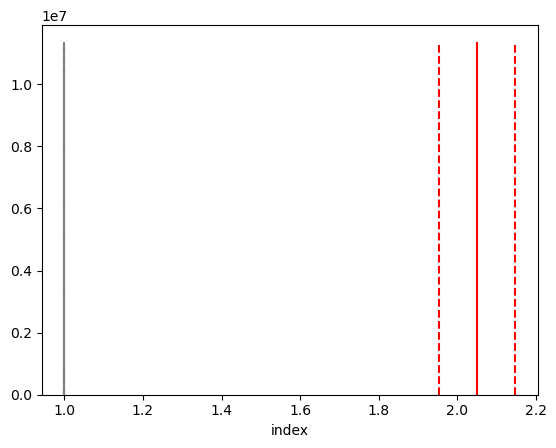

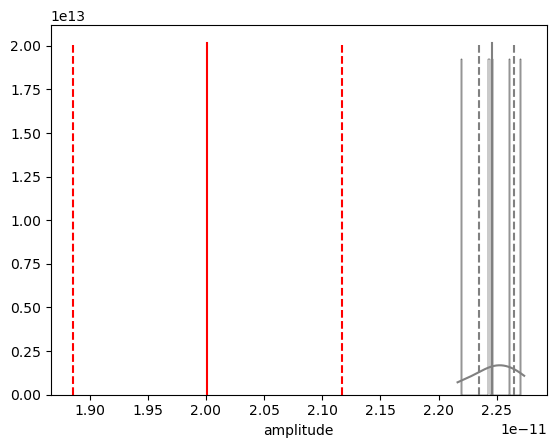

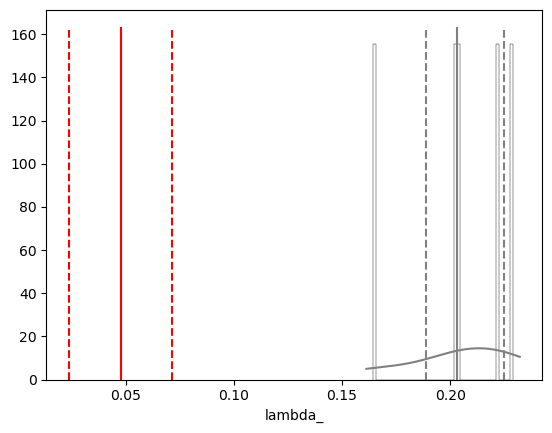

In [21]:
# let's check the fit results of the shell
for par_name in source_model.parameters.free_parameters.names:
    par_samples = []
    for k in range(n_samples):
        par_samples.append(results_samples[k].models[model_name].parameters[par_name].value)
    plt.figure()
    plt.hist(par_samples, bins=50, color="k", lw=0.3, histtype="step", density=True)
    xl=plt.xlim()
    yl = plt.ylim()
    x = np.linspace(xl[0], xl[1], 1000)
    plt.plot(x, gaussian_kde(par_samples).pdf(x), color="gray")
    plt.plot([np.percentile(par_samples, 50)]*2, yl , color="gray", ls="-", label="systematic")
    plt.plot([np.percentile(par_samples, 16)]*2, yl , color="gray", ls="--")
    plt.plot([np.percentile(par_samples, 84)]*2, yl , color="gray", ls="--")
    value = result_nominal.models[model_name].parameters[par_name].value
    error = result_nominal.models[model_name].parameters[par_name].error
    plt.plot([value]*2, yl , color="r", label="statistic")
    plt.plot([value-error]*2, yl , color="r", ls="--")
    plt.plot([value+error]*2, yl , color="r", ls="--")
    plt.xlabel(par_name)